# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Fitra Fuadi
- **Email:** mfitra166@gmail.com
- **ID Dicoding:** muhammad_fitra_fuadi

## Menentukan Pertanyaan Bisnis

Berdasarkan *Bike Sharing Dataset* (`day.csv` dan `hour.csv`) untuk periode **2011–2012**, berikut pertanyaan bisnis yang akan dijawab melalui proses analisis data:

- 1. **Pola Penyewaan Berdasarkan Jam & Jenis Hari:**  
   Bagaimana perbandingan rata-rata jumlah penyewaan sepeda (`cnt`) per jam pada hari kerja (`workingday`) dibandingkan akhir pekan/hari libur sepanjang periode tahun 2011–2012, dan pada jam berapa puncak permintaannya?

- 2. **Pengaruh Musim & Kondisi Cuaca Terhadap Penyewaan:**  
   Seberapa besar perbedaan rata-rata total penyewaan sepeda harian (`cnt`) antar musim (`season`) dan kondisi cuaca (`weathersit`) sepanjang tahun 2011–2012?

- 3. **Tren Bulanan & Komposisi Pengguna (*Casual* vs *Registered*):**  
   Bagaimana tren total penyewaan sepeda bulanan serta proporsi pengguna terdaftar (`registered`) dibandingkan pengguna kasual (`casual`) dari tahun 2011 ke tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Memuat Tabel `day_df` dan `hour_df`

In [2]:
day_df = pd.read_csv("data/bike-sharing-dataset/day.csv")
hour_df = pd.read_csv("data/bike-sharing-dataset/hour.csv")

print("Ukuran day_df:", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)

display(day_df.head())
display(hour_df.head())

Ukuran day_df: (731, 16)
Ukuran hour_df: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset berhasil dimuat ke dalam dua `DataFrame`, yaitu `day_df` sebanyak **731 baris dan 16 kolom** (data agregat harian) serta `hour_df` sebanyak **17.379 baris dan 17 kolom** (data per jam yang memiliki kolom tambahan `hr`).
- Kedua dataset mencakup informasi waktu (`dteday`, `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`), kondisi cuaca (`weathersit`, `temp`, `atemp`, `hum`, `windspeed`), serta jumlah penyewaan sepeda (`casual`, `registered`, dan `cnt`) sepanjang periode **2011–2012**.

### Assessing Data

#### Menilai Kualitas Data (`day_df` dan `hour_df`)

In [3]:
# Informasi tipe data dan non-null count
print("=== INFO day_df ===")
print(day_df.info())
print("\n=== INFO hour_df ===")
print(hour_df.info())

# Cek missing value dan duplikasi
print("\nMissing value day_df:\n", day_df.isna().sum())
print("\nMissing value hour_df:\n", hour_df.isna().sum())
print("\nDuplikasi day_df:", day_df.duplicated().sum())
print("Duplikasi hour_df:", hour_df.duplicated().sum())

# Cek nilai unik pada kolom kategori utama
cols_cat = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
for col in cols_cat:
    print(f"Unique {col} (day_df): {sorted(day_df[col].unique())}")

# Cek konsistensi cnt == casual + registered
mismatch_day = (day_df["cnt"] != (day_df["casual"] + day_df["registered"])).sum()
mismatch_hour = (hour_df["cnt"] != (hour_df["casual"] + hour_df["registered"])).sum()
print(f"\nInkonsistensi cnt pada day_df: {mismatch_day}")
print(f"Inkonsistensi cnt pada hour_df: {mismatch_hour}")

# Ringkasan statistik deskriptif
display(day_df.describe())
display(hour_df.describe())

=== INFO day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None

=== INFO hour_df ===
<class 'pandas.core.frame.DataFrame'>
RangeInd

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Mengonversi tipe data kolom `dteday` dari `object` (string) menjadi `datetime` agar operasi waktu dan pengurutan tanggal berjalan tepat.
- Memetakan nilai numerik pada kolom kategorikal (`season`, `yr`, `mnth`, `workingday`, `weathersit`) menjadi label yang lebih mudah dibaca pada tahap *cleaning*/analisis serta memastikan tipe data kategorikal sesuai.

**Insight:**
- Hasil pemeriksaan awal membantu memastikan apakah terdapat *missing value*, baris duplikat, atau ketidaksesuaian penjumlahan `casual + registered` terhadap `cnt` pada `day_df` maupun `hour_df`.
- Kolom tanggal (`dteday`) masih bertipe teks (`object`) dan kolom kategori (`season`, `yr`, `weathersit`, dll.) masih berupa angka kode sehingga perlu dirapikan pada tahap **Cleaning Data**.

### Cleaning Data

#### Membersihkan Data dan Memetakan Label Kategori

In [4]:
# Salin DataFrame agar data mentah tetap aman
day_clean = day_df.drop_duplicates().copy()
hour_clean = hour_df.drop_duplicates().copy()

# 1. Konversi kolom dteday ke tipe datetime
day_clean["dteday"] = pd.to_datetime(day_clean["dteday"])
hour_clean["dteday"] = pd.to_datetime(hour_clean["dteday"])

# 2. Pemetaan label kategori agar lebih informatif
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
yr_map = {0: 2011, 1: 2012}
mnth_map = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec",
}
workingday_map = {0: "Weekend/Holiday", 1: "Working Day"}
weathersit_map = {
    1: "Clear/Few Clouds",
    2: "Mist/Cloudy",
    3: "Light Rain/Snow",
    4: "Heavy Rain/Ice Pallets",
}

for df in [day_clean, hour_clean]:
  df["season_label"] = df["season"].map(season_map)
  df["year_label"] = df["yr"].map(yr_map)
  df["month_label"] = df["mnth"].map(mnth_map)
  df["workingday_label"] = df["workingday"].map(workingday_map)
  df["weather_label"] = df["weathersit"].map(weathersit_map)

# Urutkan berdasarkan tanggal (dan jam pada hour_clean)
day_clean = day_clean.sort_values("dteday").reset_index(drop=True)
hour_clean = hour_clean.sort_values(["dteday", "hr"]).reset_index(drop=True)

print("Tipe data dteday (day_clean):", day_clean["dteday"].dtype)
print("Tipe data dteday (hour_clean):", hour_clean["dteday"].dtype)
display(
    day_clean[[
        "dteday",
        "year_label",
        "month_label",
        "season_label",
        "workingday_label",
        "weather_label",
        "casual",
        "registered",
        "cnt",
    ]].head()
)

Tipe data dteday (day_clean): datetime64[ns]
Tipe data dteday (hour_clean): datetime64[ns]


,dteday,year_label,month_label,season_label,workingday_label,weather_label,casual,registered,cnt
0,2011-01-01,2011,Jan,Spring,Weekend/Holiday,Mist/Cloudy,331,654,985
1,2011-01-02,2011,Jan,Spring,Weekend/Holiday,Mist/Cloudy,131,670,801
2,2011-01-03,2011,Jan,Spring,Working Day,Clear/Few Clouds,120,1229,1349
3,2011-01-04,2011,Jan,Spring,Working Day,Clear/Few Clouds,108,1454,1562
4,2011-01-05,2011,Jan,Spring,Working Day,Clear/Few Clouds,82,1518,1600


**Insight:**
- Kolom `dteday` pada `day_clean` dan `hour_clean` telah berhasil dikonversi ke tipe `datetime64[ns]` dan diurutkan secara kronologis.
- Nilai numerik pada kolom `season`, `yr`, `mnth`, `workingday`, dan `weathersit` telah dipetakan menjadi label deskriptif baru sehingga lebih mudah dibaca pada tahap *Exploratory Data Analysis* (EDA) dan visualisasi.

## Exploratory Data Analysis (EDA)

### Eksplorasi Distribusi Penyewaan, Pola Jam, Musim, Cuaca, dan Tipe Pengguna

In [5]:
# 1. Statistik deskriptif penyewaan utama
display(day_clean[["casual", "registered", "cnt", "temp", "hum", "windspeed"]].describe())
display(hour_clean[["hr", "casual", "registered", "cnt"]].describe())

# 2. EDA Pertanyaan 1: Rata-rata penyewaan (cnt) per jam pada Working Day vs Weekend/Holiday
hourly_workday = (
    hour_clean.groupby(["workingday_label", "hr"], observed=False)["cnt"]
    .agg(["mean", "median", "max"])
    .reset_index()
)
display(hourly_workday.head(12))

peak_hours = (
    hourly_workday.sort_values(["workingday_label", "mean"], ascending=[True, False])
    .groupby("workingday_label", observed=False)
    .head(3)
)
print("\nTop 3 jam puncak berdasarkan rata-rata cnt:")
display(peak_hours)

# 3. EDA Pertanyaan 2: Rata-rata penyewaan harian (cnt) per musim dan kondisi cuaca
season_summary = (
    day_clean.groupby("season_label", observed=False)["cnt"]
    .agg(["count", "mean", "median", "sum"])
    .sort_values("mean", ascending=False)
)
print("\nAgregasi berdasarkan musim (day_clean):")
display(season_summary)

weather_summary = (
    day_clean.groupby("weather_label", observed=False)["cnt"]
    .agg(["count", "mean", "median", "sum"])
    .sort_values("mean", ascending=False)
)
print("\nAgregasi berdasarkan kondisi cuaca (day_clean):")
display(weather_summary)

# 4. EDA Pertanyaan 3: Tren bulanan & proporsi casual vs registered (2011 vs 2012)
monthly_users = (
    day_clean.groupby(["year_label", "mnth", "month_label"], observed=False)[
        ["casual", "registered", "cnt"]
    ]
    .sum()
    .reset_index()
    .sort_values(["year_label", "mnth"])
)
monthly_users["casual_pct"] = (monthly_users["casual"] / monthly_users["cnt"]) * 100
monthly_users["registered_pct"] = (monthly_users["registered"] / monthly_users["cnt"]) * 100
display(monthly_users)

yearly_users = day_clean.groupby("year_label", observed=False)[["casual", "registered", "cnt"]].sum()
yearly_users["casual_pct"] = (yearly_users["casual"] / yearly_users["cnt"]) * 100
yearly_users["registered_pct"] = (yearly_users["registered"] / yearly_users["cnt"]) * 100
print("\nRingkasan tahunan (2011 vs 2012):")
display(yearly_users)

,casual,registered,cnt,temp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837,0.495385,0.627894,0.190486
std,686.622488,1560.256377,1937.211452,0.183051,0.142429,0.077498
min,2.000000,20.000000,22.000000,0.059130,0.000000,0.022392
25%,315.500000,2497.000000,3152.000000,0.337083,0.520000,0.134950
50%,713.000000,3662.000000,4548.000000,0.498333,0.626667,0.180975
75%,1096.000000,4776.500000,5956.000000,0.655417,0.730209,0.233214
max,3410.000000,6946.000000,8714.000000,0.861667,0.972500,0.507463


,hr,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000
mean,11.546752,35.676218,153.786869,189.463088
std,6.914405,49.305030,151.357286,181.387599
min,0.000000,0.000000,0.000000,1.000000
25%,6.000000,4.000000,34.000000,40.000000
50%,12.000000,17.000000,115.000000,142.000000
75%,18.000000,48.000000,220.000000,281.000000
max,23.000000,367.000000,886.000000,977.000000


,workingday_label,hr,mean,median,max
0,Weekend/Holiday,0,90.800000,93.5,249
1,Weekend/Holiday,1,69.508696,71.0,168
2,Weekend/Holiday,2,53.171053,54.0,132
3,Weekend/Holiday,3,25.775330,25.0,79
4,Weekend/Holiday,4,8.264317,7.0,28
5,Weekend/Holiday,5,8.689189,7.0,55
6,Weekend/Holiday,6,18.742358,16.0,133
7,Weekend/Holiday,7,43.406926,39.0,387
8,Weekend/Holiday,8,105.653680,94.0,597
9,Weekend/Holiday,9,171.623377,170.0,397



Top 3 jam puncak berdasarkan rata-rata cnt:


,workingday_label,hr,mean,median,max
13,Weekend/Holiday,13,372.731602,367.0,760
12,Weekend/Holiday,12,366.259740,367.0,776
14,Weekend/Holiday,14,364.645022,361.0,750
41,Working Day,17,525.290581,539.0,976
42,Working Day,18,492.226908,504.5,977
32,Working Day,8,477.006048,463.0,839



Agregasi berdasarkan musim (day_clean):


... (2 outputs left out)

,count,mean,median,sum
weather_label,,,,
Clear/Few Clouds,463,4876.786177,4844.0,2257952
Mist/Cloudy,247,4035.862348,4040.0,996858
Light Rain/Snow,21,1803.285714,1817.0,37869


,year_label,mnth,month_label,casual,registered,cnt,casual_pct,registered_pct
0,2011,1,Jan,3073,35116,38189,8.046820,91.953180
1,2011,2,Feb,6242,41973,48215,12.946179,87.053821
2,2011,3,Mar,12826,51219,64045,20.026544,79.973456
3,2011,4,Apr,22346,72524,94870,23.554338,76.445662
4,2011,5,May,31050,104771,135821,22.860971,77.139029
5,2011,6,Jun,30612,112900,143512,21.330620,78.669380
6,2011,7,Jul,36452,104889,141341,25.790110,74.209890
7,2011,8,Aug,28842,107849,136691,21.100146,78.899854
8,2011,9,Sep,26545,100873,127418,20.833006,79.166994
9,2011,10,Oct,25222,98289,123511,20.420853,79.579147



Ringkasan tahunan (2011 vs 2012):


,casual,registered,cnt,casual_pct,registered_pct
year_label,,,,,
2011,247252,995851,1243103,19.889905,80.110095
2012,372765,1676811,2049576,18.187420,81.812580


**Insight:**
- Pola penyewaan per jam (`hr`) memperlihatkan perbedaan karakter antara `Working Day` dan `Weekend/Holiday`, dengan jam puncak yang berbeda sesuai aktivitas harian maupun waktu luang.
- Musim (`season_label`) dan kondisi cuaca (`weather_label`) memengaruhi rata-rata penyewaan harian (`cnt`), di mana cuaca cerah/sedikit berawan umumnya mencatat permintaan lebih tinggi dibandingkan cuaca buruk.
- Total penyewaan meningkat dari tahun 2011 ke 2012, dengan porsi pengguna `registered` mendominasi keseluruhan transaksi dibandingkan pengguna `casual`.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola Penyewaan Sepeda per Jam (Working Day vs Weekend/Holiday)

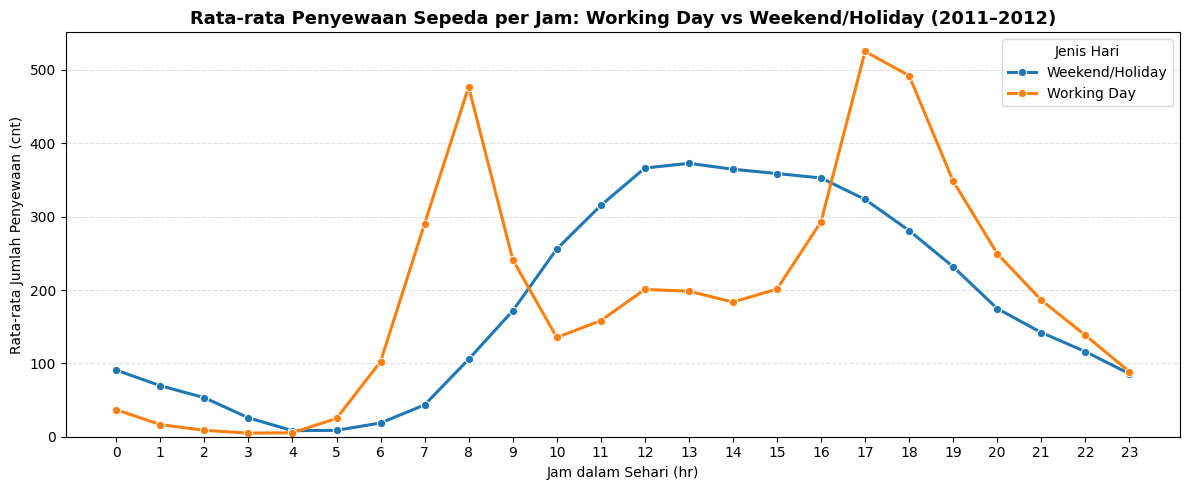

In [6]:
hourly_avg = (
    hour_clean.groupby(["workingday_label", "hr"], observed=False)["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=hourly_avg,
    x="hr",
    y="cnt",
    hue="workingday_label",
    marker="o",
    linewidth=2.2,
)
plt.title(
    "Rata-rata Penyewaan Sepeda per Jam: Working Day vs Weekend/Holiday"
    " (2011–2012)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Jam dalam Sehari (hr)")
plt.ylabel("Rata-rata Jumlah Penyewaan (cnt)")
plt.xticks(range(0, 24))
plt.ylim(bottom=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Jenis Hari")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Perbandingan Penyewaan Harian Antar Musim dan Kondisi Cuaca

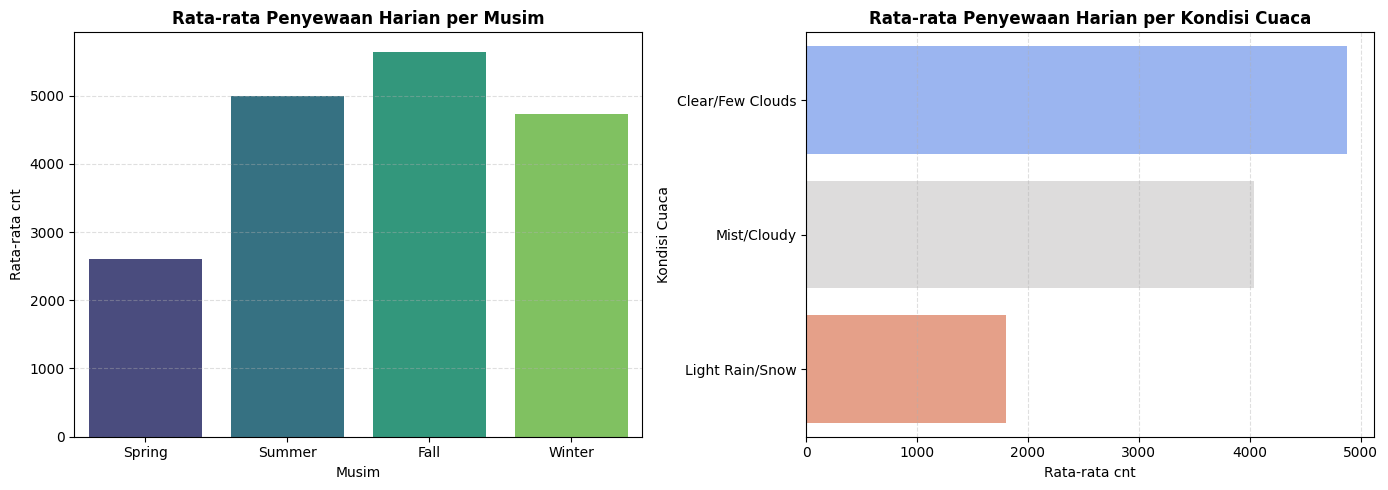

In [7]:
season_order = ["Spring", "Summer", "Fall", "Winter"]
season_avg = (
    day_clean.groupby("season_label", observed=False)["cnt"]
    .mean()
    .reindex(season_order)
    .reset_index()
)

weather_avg = (
    day_clean.groupby("weather_label", observed=False)["cnt"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=season_avg,
    x="season_label",
    y="cnt",
    hue="season_label",
    palette="viridis",
    legend=False,
    ax=axes[0],
)
axes[0].set_title(
    "Rata-rata Penyewaan Harian per Musim", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata cnt")
axes[0].set_ylim(bottom=0)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

sns.barplot(
    data=weather_avg,
    y="weather_label",
    x="cnt",
    hue="weather_label",
    palette="coolwarm",
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    "Rata-rata Penyewaan Harian per Kondisi Cuaca",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Rata-rata cnt")
axes[1].set_ylabel("Kondisi Cuaca")
axes[1].set_xlim(left=0)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### Pertanyaan 3: Tren Penyewaan Bulanan dan Komposisi Pengguna (2011–2012)

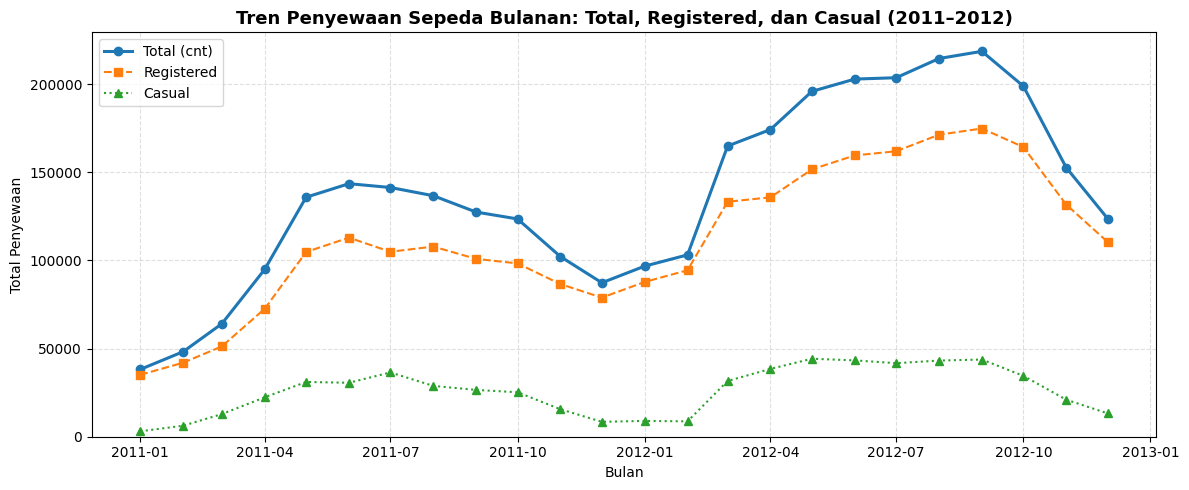

In [8]:
monthly_trend = day_clean.groupby(["year_label", "mnth"], observed=False)[
    ["casual", "registered", "cnt"]
].sum()
monthly_trend.index = pd.to_datetime(
    monthly_trend.index.map(lambda x: f"{x[0]}-{x[1]:02d}-01")
)
monthly_trend = monthly_trend.sort_index()

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_trend.index,
    monthly_trend["cnt"],
    marker="o",
    linewidth=2.2,
    label="Total (cnt)",
)
plt.plot(
    monthly_trend.index,
    monthly_trend["registered"],
    marker="s",
    linestyle="--",
    label="Registered",
)
plt.plot(
    monthly_trend.index,
    monthly_trend["casual"],
    marker="^",
    linestyle=":",
    label="Casual",
)
plt.title(
    "Tren Penyewaan Sepeda Bulanan: Total, Registered, dan Casual (2011–2012)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Bulan")
plt.ylabel("Total Penyewaan")
plt.ylim(bottom=0)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

**Insight:**
- Pada `Working Day`, rata-rata penyewaan memuncak pada jam berangkat dan pulang kerja (sekitar jam 08.00 serta 17.00–18.00), sedangkan pada `Weekend/Holiday` pola cenderung lebih landai dan memuncak pada siang hingga sore hari.
- Penyewaan harian tertinggi terjadi pada cuaca cerah/sedikit berawan (`Clear/Few Clouds`) dan menurun tajam saat cuaca memburuk, dengan perbedaan rata-rata yang jelas antar musim.
- Volume penyewaan tumbuh dari tahun 2011 ke 2012 dan didominasi oleh pengguna `registered`, sementara pengguna `casual` memiliki pola musiman/waktu luang tersendiri.

## Analisis Lanjutan (Opsional)

### Clustering Manual (Binning) Berdasarkan Kelompok Waktu dan Kategori Permintaan Harian

,workingday_label,time_group,count,mean,sum
0,Weekend/Holiday,Malam/Dini Hari (21-04),1832,74.155568,135853
1,Weekend/Holiday,Pagi (05-11),1606,132.161893,212252
2,Weekend/Holiday,Siang (12-16),1155,363.035498,419306
3,Weekend/Holiday,Sore/Malam Awal (17-20),921,252.831705,232858
4,Working Day,Malam/Dini Hari (21-04),3911,61.721555,241393
5,Working Day,Pagi (05-11),3471,204.358398,709328
6,Working Day,Siang (12-16),2490,215.492369,536576
7,Working Day,Sore/Malam Awal (17-20),1993,403.970396,805113


,demand_category,jumlah_hari
0,Rendah (<2000),98
1,Sedang (2000-4500),261
2,Tinggi (>4500),372


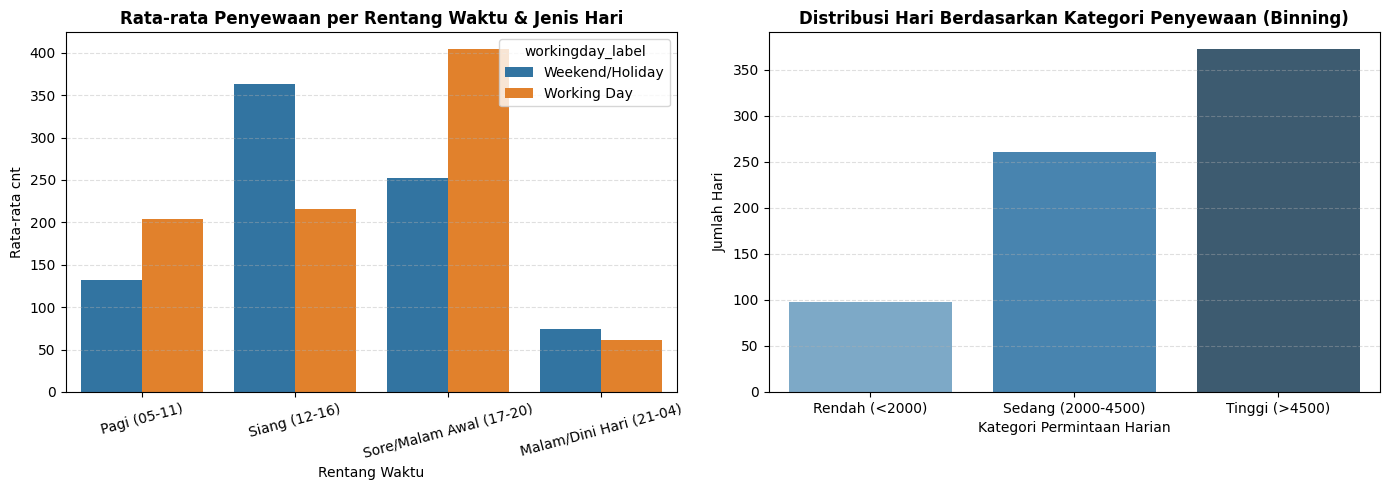

In [9]:
# 1. Manual Grouping rentang waktu dalam sehari pada hour_clean
def categorize_time_of_day(hr):
  if 5 <= hr < 12:
    return "Pagi (05-11)"
  elif 12 <= hr < 17:
    return "Siang (12-16)"
  elif 17 <= hr < 21:
    return "Sore/Malam Awal (17-20)"
  else:
    return "Malam/Dini Hari (21-04)"


hour_clean["time_group"] = hour_clean["hr"].apply(categorize_time_of_day)
time_group_summary = (
    hour_clean.groupby(["workingday_label", "time_group"], observed=False)["cnt"]
    .agg(["count", "mean", "sum"])
    .reset_index()
)
display(time_group_summary)

# 2. Binning kategori volume penyewaan harian (cnt) pada day_clean
bins = [0, 2000, 4500, day_clean["cnt"].max() + 1]
labels = ["Rendah (<2000)", "Sedang (2000-4500)", "Tinggi (>4500)"]
day_clean["demand_category"] = pd.cut(
    day_clean["cnt"], bins=bins, labels=labels, right=False
)

demand_dist = (
    day_clean["demand_category"].value_counts().reindex(labels).reset_index()
)
demand_dist.columns = ["demand_category", "jumlah_hari"]
display(demand_dist)

# Visualisasi analisis lanjutan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_time = [
    "Pagi (05-11)",
    "Siang (12-16)",
    "Sore/Malam Awal (17-20)",
    "Malam/Dini Hari (21-04)",
]
sns.barplot(
    data=time_group_summary,
    x="time_group",
    y="mean",
    hue="workingday_label",
    order=order_time,
    ax=axes[0],
)
axes[0].set_title(
    "Rata-rata Penyewaan per Rentang Waktu & Jenis Hari",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Rentang Waktu")
axes[0].set_ylabel("Rata-rata cnt")
axes[0].tick_params(axis="x", rotation=15)
axes[0].set_ylim(bottom=0)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

sns.barplot(
    data=demand_dist,
    x="demand_category",
    y="jumlah_hari",
    hue="demand_category",
    palette="Blues_d",
    legend=False,
    ax=axes[1],
)
axes[1].set_title(
    "Distribusi Hari Berdasarkan Kategori Penyewaan (Binning)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Kategori Permintaan Harian")
axes[1].set_ylabel("Jumlah Hari")
axes[1].set_ylim(bottom=0)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan:**
- Berdasarkan pengelompokan waktu (`time_group`), pada **Working Day** rata-rata penyewaan tertinggi terjadi pada rentang **Sore/Malam Awal (17–20)** sebesar **403,97** penyewaan/jam (total **805.113** penyewaan), sedangkan pada **Weekend/Holiday** puncak bergeser ke **Siang (12–16)** dengan rata-rata **363,04** penyewaan/jam (total **419.306** penyewaan).
- Berdasarkan *binning* permintaan harian (`demand_category`) dari total 731 hari, mayoritas hari masuk kategori **Tinggi (>4.500)** sebanyak **372 hari (50,89%)**, diikuti kategori **Sedang (2.000–4.500)** sebanyak **261 hari (35,70%)**, dan kategori **Rendah (<2.000)** sebanyak **98 hari (13,41%)**.

## Conclusion & Recommendation

### Conclusion
- **Conclusion Pertanyaan 1 (Pola Jam & Hari Kerja vs Hari Libur):**
  - Pada **Working Day**, penyewaan menunjukkan dua jam puncak komuter yang jelas, yaitu pagi hari pukul **08:00** dengan rata-rata **477,01** penyewaan/jam dan puncak tertinggi pada sore hari pukul **17:00** dengan rata-rata **525,29** penyewaan/jam (diikuti pukul **18:00** sebesar **492,23** penyewaan/jam).
  - Pada **Weekend/Holiday**, penyewaan memuncak pada siang hari tepatnya pukul **13:00** dengan rata-rata **372,73** penyewaan/jam (diikuti pukul **12:00** sebesar **366,26** dan pukul **14:00** sebesar **364,65** penyewaan/jam).
  - Jam puncak tertinggi pada **Working Day** (pukul 17:00) lebih tinggi **152,56** penyewaan/jam (**40,93%**) dibandingkan puncak **Weekend/Holiday** (pukul 13:00). Secara keseluruhan rata-rata per jam, **Working Day** mencatat **193,21** penyewaan/jam dibandingkan **181,41** penyewaan/jam pada **Weekend/Holiday**, atau berselisih **11,80** penyewaan/jam (**6,51%** lebih tinggi).

- **Conclusion Pertanyaan 2 (Musim & Kondisi Cuaca):**
  - Berdasarkan **musim**, rata-rata penyewaan harian tertinggi terjadi pada musim **Fall** (**5.644,30** penyewaan/hari), diikuti **Summer** (**4.992,33**), **Winter** (**4.728,16**), dan terendah pada **Spring** (**2.604,13**). Rata-rata pada musim **Fall** lebih tinggi **3.040,17** penyewaan/hari (**116,74%** lebih tinggi) dibandingkan **Spring** (atau **Spring** lebih rendah **53,86%** dibanding **Fall**), serta unggul **13,06%** atas **Summer** dan **19,38%** atas **Winter**.
  - Berdasarkan **kondisi cuaca**, rata-rata tertinggi berada pada kondisi **Clear/Few Clouds** (**4.876,79** penyewaan/hari selama 463 hari), diikuti **Mist/Cloudy** (**4.035,86** penyewaan/hari selama 247 hari), dan terendah pada **Light Rain/Snow** (**1.803,29** penyewaan/hari). Dibandingkan **Clear/Few Clouds**, rata-rata penyewaan turun sebesar **840,92** penyewaan/hari (**-17,24%**) saat **Mist/Cloudy** dan anjlok sebesar **3.073,50** penyewaan/hari (**-63,02%**) saat **Light Rain/Snow** (atau **Clear/Few Clouds** lebih tinggi **170,44%** dibanding **Light Rain/Snow**).
  - Kategori cuaca yang jarang terjadi pada data harian (`day.csv`) adalah **Light Rain/Snow** yang hanya berlangsung selama **21 hari (2,87%** dari total 731 hari), sementara kategori ekstrem **Heavy Rain/Ice Pallets** tidak tercatat sebagai kondisi harian (**0 hari** pada `day.csv`).

- **Conclusion Pertanyaan 3 (Tren Tahunan, Bulan Puncak, & Komposisi Pengguna):**
  - Total penyewaan meningkat signifikan dari **1.243.103** penyewaan pada tahun **2011** menjadi **2.049.576** penyewaan pada tahun **2012**, atau tumbuh sebesar **806.473** penyewaan (**+64,88%**).
  - **Bulan puncak** penyewaan pada tahun 2011 terjadi di bulan **Juni 2011** dengan total **143.512** penyewaan, sedangkan pada tahun 2012 (sekaligus puncak tertinggi keseluruhan) terjadi di bulan **September 2012** dengan total **218.573** penyewaan (diikuti Agustus 2012 sebesar 214.503).
  - Komposisi pengguna didominasi oleh segmen `registered` di kedua tahun: pada **2011** pengguna `registered` mencapai **80,11%** (995.851 penyewaan) dan `casual` **19,89%** (247.252 penyewaan), sedangkan pada **2012** pengguna `registered` meningkat menjadi **81,81%** (1.676.811 penyewaan) dan `casual` **18,19%** (372.765 penyewaan).

### Recommendation
- **Rebalancing Armada Berdasarkan Jam Puncak:** Tingkatkan distribusi dan ketersediaan sepeda di titik komuter (stasiun/perkantoran) menjelang pukul **08:00** dan **17:00–18:00** pada hari kerja, serta alihkan fokus ke area rekreasi pada rentang **12:00–16:00** (puncak pukul **13:00**) saat akhir pekan/hari libur.
- **Penjadwalan Perawatan & Promo Saat Periode Sepi:** Manfaatkan periode permintaan terendah—khususnya musim **Spring** (rata-rata 2.604,13/hari) dan hari dengan cuaca buruk (**Light Rain/Snow**)—untuk perawatan rutin armada serta program promosi musiman agar utilisasi tetap terjaga.
- **Retensi Pengguna `registered` & Konversi `casual`:** Pertahankan loyalitas pengguna `registered` (yang berkontribusi lebih dari 80% transaksi) melalui manfaat keanggotaan jangka panjang, dan luncurkan promo *weekend pass* atau diskon langganan perdana saat puncak musiman (**Juni–September**) untuk mengonversi pengguna `casual` menjadi pelanggan terdaftar.

In [10]:
import os

os.makedirs("dashboard", exist_ok=True)
day_clean.to_csv("dashboard/main_data.csv", index=False)
print("Berhasil menyimpan dashboard/main_data.csv")

Berhasil menyimpan dashboard/main_data.csv
